# Implementacion de mejoras del MVP para el Trabajo Final

## 1. Evaluacion del agente RAG

Conforme a la planificación establecida en el roadmap del MVP, durante esta etapa final se diseñaron e implementaron las metodologías de evaluación cuantitativa para auditar el desempeño de nuestro agente.

Esta auditoría se consolidó en los `notebooks notebooks/02_evaluacion_rag.ipynb` y `notebooks/03_evaluacion_modelos_embedding.ipynb`. Utilizando LangSmith como plataforma de observabilidad y evaluación, se contrastó la arquitectura RAG contra una línea de base (baseline) léxica basada en **TF-IDF** sobre un dataset de pruebas (**Ground Truth**) generado mediante eventos de seguridad controlados. Este experimento constató que un SIEM tradicional como Wazuh presenta vacíos al etiquetar nativamente ciertos eventos con su técnica de **MITRE ATT&CK**, mientras que la búsqueda semántica del RAG demostró una clara superioridad cuantitativa.

Posteriormente, se realizó una evaluación comparativa entre cuatro modelos de embeddings (tres alternativas gratuitas y el modelo **gemini-embedding-001**). Los resultados posicionaron a Gemini como el modelo ganador con una tasa de acierto **Hit@5** del **67.74%** y un **MRR** de **0.4866**.

## 2. Acotar el alcance

Con el propósito de maximizar la precisión del sistema, garantizar la viabilidad de las pruebas experimentales y mantener un enfoque riguroso en el núcleo del RAG, se realizó una delimitación estratégica del alcance del agente.

En este proceso, se desestimaron tres verticales de ciberseguridad originalmente contempladas: *Seguridad Web*, *Tecnología Operativa (OT)* y *Seguridad Móvil (Mobile)*. Esta decisión técnica se fundamentó en dos motivos principales:

* *Ausencia de integraciones operativas (Tools):* Dichos dominios no contaban con herramientas ni APIs activas que permitieran una interacción ejecutable por parte del agente.

* *Viabilidad del plan de pruebas:* Al no disponer de un entorno simulado representativo para la generación de eventos en estas áreas, mantenerlas comprometía la evaluabilidad objetiva de la arquitectura.

Tras esta reestructuración, la arquitectura del agente (implementada mediante un grafo de estados) se consolidó alrededor de un nodo central de enrutamiento (router) que distribuye el flujo de trabajo hacia tres áreas especializadas, cada una dotada con su correspondiente conjunto de herramientas ejecutable:

* **Infraestructura y Redes (infraestructura_redes):** Especializado en el análisis y consulta de topología de red, interactuando de forma iterativa con infra_tools.

* **Análisis de Logs de SOC (soc_logs):** Centrado en el procesamiento y enriquecimiento de telemetría de seguridad (integrado directamente con herramientas como Wazuh) a través de soc_tools.

* **Inteligencia de Amenazas (threat_intel):** Encargado de la contextualización de cibercriminales, tácticas y técnicas (RAG sobre frameworks como MITRE ATT&CK), empleando threat_tools.


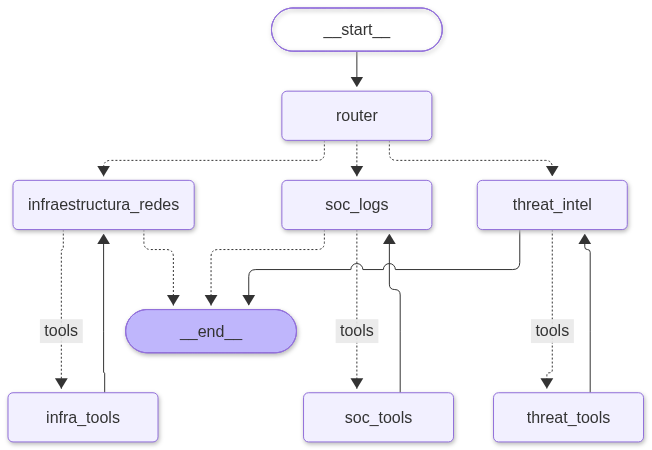

## 3. Correcciones minimas

En respuesta a las observaciones recibidas sobre el MVP, se efectuaron los siguientes ajustes en el código, la seguridad del agente y la documentación del proyecto:

* **Alineación de Prompts con las Capacidades Reales (`Notebook 05`):** En el notebook `notebooks/05_demo_trabajo_final.ipynb`, se reestructuraron los casos de uso demostrativos del módulo de *Threat Intelligence*. Se removieron las solicitudes relativas al análisis de hashes y reputación de IP —las cuales requerían servicios externos no integrados—, alineando de manera estricta las consignas con la resolución de problemas mediante la arquitectura RAG desarrollada.

* **Hardening y Validación de Argumentos en `nmap`:** Para prevenir riesgos de inyección de parámetros o ejecuciones no controladas derivadas del texto de una alerta o alucinación del modelo, se implementó una **lista blanca (*allowlist*) de argumentos permitidos** para la herramienta de escaneo. Con esto, el agente valida de forma rigurosa tanto la dirección de destino como los *flags* de escaneo autorizados.

* **Depuración y Sincronización del `README.md`:** Se actualizó la documentación principal del repositorio eliminando referencias obsoletas (como la mención al módulo inexistente `firewall_tool.py`) y reflejando fielmente la estructura de archivos, herramientas e integraciones actualmente funcionales.

## 4. Mejoras

Se realizaron tambien las siguientes mejores:

* **Implementacion de `Rich` en la interfaz**: Se implemento el framework de rich en la interfaz para hacer el agente mas a meno al usuario

* **Tool de reportes en pdf**: Ademas de reportes en formato markdown es sumamente util tener la misma funcionalidad para formato pdf